# URTIC cold vs non-cold speech classification — clean, reproducible pipeline

This notebook is self-contained: restart the kernel, then run every cell from top to bottom. It uses one manifest and one cache format only. It deliberately **does not load older cache folders**, because the earlier notebooks used incompatible cache names and feature definitions.

The representation is 65-dimensional per 10 ms frame: 39 MFCC/delta features, 8 lightweight voice-quality features, TEO-FM variance, TEO autocorrelation-envelope area, and 16 TEO critical-band autocorrelation-envelope values. The voice-quality and critical-band quantities are fast, transparent signal-processing proxies suitable for a CPU-aware baseline; validate any clinical interpretation separately.

UAR is selected on development data. Test labels are used once, at the end. No UAR target is guaranteed.


In [1]:
# 1. Install missing dependencies and configure the run
import importlib.util, subprocess, sys
REQUIRED = {"numpy":"numpy", "pandas":"pandas", "scipy":"scipy", "librosa":"librosa", "soundfile":"soundfile", "sklearn":"scikit-learn", "matplotlib":"matplotlib", "seaborn":"seaborn", "tqdm":"tqdm", "torch":"torch"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

import os, json, time, hashlib, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import librosa
from scipy import signal
from scipy.signal import hilbert
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score, accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

warnings.filterwarnings("ignore")
SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
CPU_THREADS = max(1, min(6, os.cpu_count() or 4)); torch.set_num_threads(CPU_THREADS)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Only change URTIC_ROOT if your dataset resides elsewhere.
URTIC_ROOT = Path(r"E:\Final Year Project\dataset\URTIC")
OUTPUT_ROOT = URTIC_ROOT / "cold_conformer_output"
CACHE_DIR = OUTPUT_ROOT / "feature_cache_v4"       # the sole cache used by this notebook
RESULTS_DIR = OUTPUT_ROOT / "results_v4"
CACHE_DIR.mkdir(parents=True, exist_ok=True); RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Fast mode is intentionally bounded for a typical Windows laptop. Set max_seconds=5 or 6 only after benchmarking.
CFG = dict(version="urtic_teo_v4", sr=16000, frame_ms=25, hop_ms=10, trim_db=30, preemph=0.97,
           max_seconds=3.0, n_mfcc=13, n_mels=40, n_teo_bands=16, temporal_pool=4,
           d_model=80, nhead=4, num_layers=2, ff_mult=2, dropout=0.20,
           batch_size=32 if DEVICE.type == "cuda" else 16, epochs=14, patience=4,
           lr=3e-4, weight_decay=1e-3, focal_gamma=1.5, num_workers=0)
FRAME = int(CFG["sr"] * CFG["frame_ms"] / 1000); HOP = int(CFG["sr"] * CFG["hop_ms"] / 1000)
FEATURE_DIM = 65

# None processes every discovered file. Use a small integer only to smoke-test a new installation.
CACHE_LIMIT_PER_SPLIT = None
print(f"Device: {DEVICE}; CPU threads: {CPU_THREADS}")
print("Canonical cache:", CACHE_DIR)
if not URTIC_ROOT.exists():
    raise FileNotFoundError(f"URTIC_ROOT does not exist: {URTIC_ROOT}. Edit that one path in this cell.")


c:\Users\Srichaitanya Panda\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu; CPU threads: 6
Canonical cache: E:\Final Year Project\dataset\URTIC\cold_conformer_output\feature_cache_v4


In [2]:
# 2. Discover train/dev/test and build the one authoritative manifest
AUDIO_EXTENSIONS = {".wav", ".flac", ".mp3", ".ogg", ".m4a"}
NONCOLD_WORDS = {"noncold", "non_cold", "non-cold", "control", "healthy", "normal", "nocold", "no_cold"}
SPLIT_ALIASES = {"train": {"train", "training"}, "dev": {"dev", "develop", "development", "valid", "validation", "val"}, "test": {"test", "testing"}}

def find_split(root, aliases):
    candidates = [p for p in root.rglob("*") if p.is_dir() and p.name.lower() in aliases]
    if not candidates: return None
    return min(candidates, key=lambda p: (len(p.parts), str(p).lower()))

def label_of(path):
    parts = [x.lower().replace(" ", "_") for x in Path(path).parts]
    if any(x in NONCOLD_WORDS for x in parts): return "noncold"
    if any("cold" in x and "non" not in x and "no_" not in x for x in parts): return "cold"
    return None

split_dirs = {name: find_split(URTIC_ROOT, aliases) for name, aliases in SPLIT_ALIASES.items()}
print("Split folders:", split_dirs)
if any(p is None for p in split_dirs.values()):
    raise FileNotFoundError("Could not find all train/dev/test folders under URTIC_ROOT.")

rows = []
for split, folder in split_dirs.items():
    files = sorted(p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in AUDIO_EXTENSIONS)
    for audio in files:
        label = label_of(audio)
        if label is not None:
            # Folder immediately above the class folder is a conservative speaker guess; replace with a real ID if available.
            relative = audio.relative_to(folder)
            speaker_id = relative.parts[-3] if len(relative.parts) >= 3 else audio.stem.split("_")[0]
            rows.append({"audio_path": str(audio.resolve()), "split": split, "label": label, "speaker_id": speaker_id})
manifest = pd.DataFrame(rows)
if manifest.empty: raise RuntimeError("No labelled audio found. Expected class folders named cold and noncold/control/healthy.")
manifest["target"] = manifest["label"].map({"noncold":0, "cold":1})
if manifest.target.isna().any() or manifest.label.nunique() != 2: raise ValueError("Expected exactly cold and noncold labels.")
counts = manifest.groupby(["split", "label"]).size().unstack(fill_value=0)
print(counts)
if set(manifest.split) != {"train", "dev", "test"} or (counts == 0).any().any():
    raise ValueError("Every split must contain both classes. Check the folder layout/label names.")
for left, right in [("train","dev"), ("train","test"), ("dev","test")]:
    overlap = set(manifest.query("split == @left").speaker_id) & set(manifest.query("split == @right").speaker_id)
    if overlap: print(f"WARNING: heuristic speaker IDs overlap between {left}/{right}: {list(overlap)[:5]}. Verify speaker-disjoint splits.")
manifest.to_csv(RESULTS_DIR / "manifest_v3.csv", index=False)
display(manifest.head())


Split folders: {'train': WindowsPath('E:/Final Year Project/dataset/URTIC/train'), 'dev': WindowsPath('E:/Final Year Project/dataset/URTIC/develop'), 'test': WindowsPath('E:/Final Year Project/dataset/URTIC/test')}
label  cold  noncold
split               
dev    1011     8585
test    894     8655
train   970     8532


,audio_path,split,label,speaker_id,target
0,E:\Final Year Project\dataset\URTIC\train\cold...,train,cold,train,1
1,E:\Final Year Project\dataset\URTIC\train\cold...,train,cold,train,1
2,E:\Final Year Project\dataset\URTIC\train\cold...,train,cold,train,1
3,E:\Final Year Project\dataset\URTIC\train\cold...,train,cold,train,1
4,E:\Final Year Project\dataset\URTIC\train\cold...,train,cold,train,1


In [3]:
# 3. Fast 65-D TEO + voice-feature extractor and cache contract
EPS = 1e-10
FEATURE_NAMES = ([f"mfcc_{i+1}" for i in range(13)] + [f"delta_mfcc_{i+1}" for i in range(13)] + [f"delta2_mfcc_{i+1}" for i in range(13)] +
                 ["log_rms", "zcr", "centroid", "rolloff85", "flatness", "f0_hz", "hnr_proxy_db", "cpp_proxy"] +
                 ["teo_fm_var", "teo_auto_env"] + [f"teo_cb_auto_env_{i+1}" for i in range(CFG["n_teo_bands"])])
assert len(FEATURE_NAMES) == FEATURE_DIM
CFG_FINGERPRINT = hashlib.sha256(json.dumps({k:CFG[k] for k in ["version","sr","frame_ms","hop_ms","trim_db","preemph","max_seconds","n_mfcc","n_mels","n_teo_bands"]}, sort_keys=True).encode()).hexdigest()[:16]

def preprocess_audio(path):
    y, source_sr = librosa.load(str(path), sr=None, mono=True)
    if y.size == 0: raise ValueError("empty audio")
    y = librosa.resample(y, orig_sr=source_sr, target_sr=CFG["sr"]) if source_sr != CFG["sr"] else y
    y = np.asarray(y, dtype=np.float32); y -= y.mean()
    intervals = librosa.effects.split(y, top_db=CFG["trim_db"], frame_length=FRAME, hop_length=HOP)
    if len(intervals): y = np.concatenate([y[a:b] for a,b in intervals])
    y = .98 * y / max(float(np.max(np.abs(y))), EPS)
    y = signal.lfilter([1., -CFG["preemph"]], [1.], y).astype(np.float32)
    y = y[:int(CFG["max_seconds"] * CFG["sr"])]
    return np.pad(y, (0, max(0, FRAME-len(y))))

def frames(y):
    remainder = (len(y)-FRAME) % HOP
    if remainder: y = np.pad(y, (0, HOP-remainder))
    return librosa.util.frame(y, frame_length=FRAME, hop_length=HOP).T * np.hanning(FRAME)

def teo(x):
    x = np.asarray(x, np.float64); out = np.zeros_like(x)
    if len(x) > 2: out[1:-1] = x[1:-1]**2 - x[:-2]*x[2:]
    return out

def env_area(x):
    p = teo(x); p -= p.mean()
    if np.dot(p,p) <= EPS: return 0.
    ac = signal.correlate(p, p, mode="full", method="fft")[len(p)-1:]
    ac /= max(ac[0], EPS)
    return float(np.trapezoid(np.abs(hilbert(ac))[1:]) / max(1, len(ac)-1))

def erb_edges(n, fmin, fmax):
    erb = lambda f: 21.4*np.log10(4.37e-3*f + 1)
    inv = lambda e: (10**(e/21.4)-1)/4.37e-3
    return inv(np.linspace(erb(fmin), erb(fmax), n+1))

def extract_features(path):
    y = preprocess_audio(path); fr = frames(y); n = len(fr)
    # center=False guarantees all librosa tracks have n frames.
    mfcc = librosa.feature.mfcc(y=y, sr=CFG["sr"], n_mfcc=13, n_mels=40, n_fft=512, hop_length=HOP, win_length=FRAME, center=False)
    delta = librosa.feature.delta(mfcc, width=5); delta2 = librosa.feature.delta(mfcc, order=2, width=5)
    mag = np.abs(librosa.stft(y, n_fft=512, hop_length=HOP, win_length=FRAME, center=False))
    freq = librosa.fft_frequencies(sr=CFG["sr"], n_fft=512)[:,None]
    power = mag**2; pnorm = power / np.maximum(power.sum(axis=0, keepdims=True), EPS)
    rms = np.sqrt(np.mean(fr**2,axis=1)+EPS); zcr = np.mean(np.diff(np.signbit(fr),axis=1)!=0,axis=1)
    centroid = (freq*pnorm).sum(axis=0); csum = np.cumsum(pnorm,axis=0); rolloff = freq[np.argmax(csum >= .85,axis=0),0]
    flatness = np.exp(np.mean(np.log(power+EPS),axis=0)) / (np.mean(power,axis=0)+EPS)
    # F0/HNR/CPP proxies from a short-lag autocorrelation: no Praat dependency and bounded cost.
    f0=np.zeros(n); hnr=np.zeros(n); cpp=np.zeros(n)
    lo,hi=max(1,int(CFG["sr"]/400)),min(FRAME-2,int(CFG["sr"]/60))
    for i,x in enumerate(fr):
        ac=signal.correlate(x-x.mean(),x-x.mean(),mode="full",method="fft")[FRAME-1:]; peak=ac[lo:hi]
        if ac[0] > EPS and len(peak):
            r=float(np.clip(peak.max()/(ac[0]+EPS),0,.999999)); lag=lo+int(peak.argmax()); f0[i]=CFG["sr"]/lag; hnr[i]=10*np.log10((r+EPS)/(1-r+EPS))
        cep=np.fft.irfft(np.log(mag[:,min(i,mag.shape[1]-1)]+EPS)); q=cep[lo:hi]
        if len(q)>3: cpp[i]=q.max()-np.median(q)
    psi=teo(y); omega=np.diff(psi,prepend=psi[0]); fm=np.asarray([np.var(omega[i*HOP:i*HOP+FRAME]) for i in range(n)])
    # TEO values are utterance-level stable descriptors repeated at each frame. The critical-band branch runs at 8 kHz,
    # then uses a 2 kHz analysis stream for the autocorrelation-envelope statistic: a reproducible speed/CPU trade-off.
    teo_sr=8000; y_teo=signal.resample_poly(y,1,2); global_teo=env_area(y_teo[::4]); edges=erb_edges(CFG["n_teo_bands"],80,teo_sr/2-100); cb=[]
    for low, high in zip(edges[:-1],edges[1:]):
        sos=signal.butter(2,[low/(teo_sr/2),high/(teo_sr/2)],btype="bandpass",output="sos")
        cb.append(env_area(signal.sosfilt(sos,y_teo)[::4]))
    # librosa's 512-point STFT can have fewer frames than 400-sample manual frames; crop *before* column_stack.
    m=min(n,mfcc.shape[1],delta.shape[1],delta2.shape[1],mag.shape[1],len(rms),len(zcr),len(centroid),len(rolloff),len(flatness),len(f0),len(hnr),len(cpp),len(fm))
    voice=np.column_stack([np.log(rms[:m]+EPS),zcr[:m],centroid[:m],rolloff[:m],flatness[:m],f0[:m],hnr[:m],cpp[:m]])
    teo_block=np.column_stack([fm[:m], np.full(m,global_teo), np.tile(np.asarray(cb),(m,1))])
    x=np.concatenate([mfcc[:,:m].T,delta[:,:m].T,delta2[:,:m].T,voice,teo_block],axis=1)
    x=np.nan_to_num(x,nan=0.,posinf=0.,neginf=0.).astype(np.float32)
    if x.ndim!=2 or x.shape[1]!=FEATURE_DIM or not len(x): raise ValueError(f"invalid feature shape {x.shape}")
    return x

def cache_path(path):
    p=Path(path); stamp=f"{p.resolve()}|{p.stat().st_size}|{p.stat().st_mtime_ns}|{CFG_FINGERPRINT}"
    return CACHE_DIR / (hashlib.sha256(stamp.encode()).hexdigest()+".npz")

def cached_features(path):
    out=cache_path(path)
    if out.exists():
        try:
            with np.load(out, allow_pickle=False) as z:
                if z["x"].ndim==2 and z["x"].shape[1]==FEATURE_DIM and str(z["fingerprint"].item())==CFG_FINGERPRINT: return out
        except Exception: pass
    x=extract_features(path); tmp=out.with_suffix(".tmp.npz")
    np.savez_compressed(tmp,x=x,fingerprint=np.array(CFG_FINGERPRINT)); tmp.replace(out)
    return out
print("Feature dimensions:", len(FEATURE_NAMES), "| cache fingerprint:", CFG_FINGERPRINT)


Feature dimensions: 65 | cache fingerprint: 2cb7f29c16fb7670


In [4]:
# 4. Benchmark then build/reuse the cache. Safe to rerun: valid files are skipped.
probe = manifest.iloc[0].audio_path
t0=time.perf_counter(); probe_cache=cached_features(probe); elapsed=time.perf_counter()-t0
with np.load(probe_cache, allow_pickle=False) as z: print("Probe:", z["x"].shape, "seconds:", round(elapsed,2), "NaN:", np.isnan(z["x"]).sum())
remaining = sum(not cache_path(p).exists() for p in manifest.audio_path)
print(f"Estimated extraction time from this one file: ~{remaining*elapsed/60:.1f} minutes. This is an estimate; storage and duration vary.")

cache_records=[]; failures=[]
for split in ("train","dev","test"):
    part=manifest[manifest.split.eq(split)]
    if CACHE_LIMIT_PER_SPLIT is not None: part=part.iloc[:CACHE_LIMIT_PER_SPLIT]
    for idx,row in tqdm(part.iterrows(), total=len(part), desc=f"Caching {split}"):
        try: cache_records.append((idx,str(cached_features(row.audio_path))))
        except Exception as exc: failures.append({"audio_path":row.audio_path,"error":repr(exc)})
if failures:
    pd.DataFrame(failures).to_csv(RESULTS_DIR/"cache_failures.csv",index=False); print("Failures:",len(failures),"(saved to cache_failures.csv)")
cache_df=pd.DataFrame(cache_records,columns=["row","cache_path"])
manifest=manifest.join(cache_df.set_index("row"),how="left")
manifest=manifest[manifest.cache_path.notna()].copy(); manifest.to_csv(RESULTS_DIR/"manifest_cached_v3.csv",index=False)
if CACHE_LIMIT_PER_SPLIT is not None: raise RuntimeError("Smoke test completed. Set CACHE_LIMIT_PER_SPLIT = None and rerun this cell before training.")
print("Cached usable files:",len(manifest),"of",len(rows))


Probe: (297, 65) seconds: 0.01 NaN: 0
Estimated extraction time from this one file: ~0.3 minutes. This is an estimate; storage and duration vary.


Caching test: 100%|██████████| 9549/9549 [06:43<00:00, 23.66it/s] 


Failures: 1 (saved to cache_failures.csv)
Cached usable files: 28646 of 28647


In [5]:
# 5. Fit train-only normalization, validate dimensions, and make Windows-safe datasets
train_paths=manifest.query("split=='train'").cache_path.tolist()
scaler=StandardScaler()
for path in tqdm(train_paths,desc="Fitting train scaler"):
    with np.load(path,allow_pickle=False) as z:
        x=z["x"]
    if x.shape[1]!=FEATURE_DIM: raise ValueError(f"Bad cache dimensions: {path}: {x.shape}")
    scaler.partial_fit(x)
np.savez(RESULTS_DIR/"train_scaler_v3.npz",mean=scaler.mean_,scale=scaler.scale_,feature_names=np.asarray(FEATURE_NAMES))

class SpeechDataset(Dataset):
    def __init__(self, table): self.t=table.reset_index(drop=True)
    def __len__(self): return len(self.t)
    def __getitem__(self,i):
        row=self.t.iloc[i]
        with np.load(row.cache_path,allow_pickle=False) as z: x=z["x"].astype(np.float32)
        x=(x-scaler.mean_)/np.maximum(scaler.scale_,1e-6); x=np.clip(x,-8,8)
        return torch.from_numpy(x), int(row.target), row.audio_path

def collate(batch):
    xs,ys,names=zip(*batch); lengths=torch.tensor([len(x) for x in xs]); maxlen=int(lengths.max())
    x=torch.zeros(len(xs),maxlen,FEATURE_DIM)
    for i,item in enumerate(xs): x[i,:len(item)]=item
    return x,torch.tensor(ys),lengths,list(names)

splits={s:manifest[manifest.split.eq(s)].copy() for s in ("train","dev","test")}
datasets={s:SpeechDataset(t) for s,t in splits.items()}
counts=np.bincount(splits["train"].target.astype(int),minlength=2); weights=1.0/counts[splits["train"].target.astype(int).to_numpy()]
sampler=WeightedRandomSampler(weights,len(weights),replacement=True,generator=torch.Generator().manual_seed(SEED))
loaders={"train":DataLoader(datasets["train"],batch_size=CFG["batch_size"],sampler=sampler,num_workers=CFG["num_workers"],collate_fn=collate),
         "dev":DataLoader(datasets["dev"],batch_size=CFG["batch_size"],shuffle=False,num_workers=0,collate_fn=collate),
         "test":DataLoader(datasets["test"],batch_size=CFG["batch_size"],shuffle=False,num_workers=0,collate_fn=collate)}
print("Train class counts [noncold,cold]:",counts,"| feature dim:",FEATURE_DIM)


Fitting train scaler: 100%|██████████| 9502/9502 [00:33<00:00, 279.65it/s]

Train class counts [noncold,cold]: [8532  970] | feature dim: 65


In [6]:
# 6. Compact Conformer and UAR-oriented training
class ConformerBlock(nn.Module):
    def __init__(self,d):
        super().__init__(); self.ff1=nn.Sequential(nn.LayerNorm(d),nn.Linear(d,d*CFG["ff_mult"]),nn.SiLU(),nn.Dropout(CFG["dropout"]),nn.Linear(d*CFG["ff_mult"],d))
        self.attn_norm=nn.LayerNorm(d); self.attn=nn.MultiheadAttention(d,CFG["nhead"],dropout=CFG["dropout"],batch_first=True)
        self.conv_norm=nn.LayerNorm(d); self.conv=nn.Sequential(nn.Conv1d(d,2*d,1),nn.GLU(dim=1),nn.Conv1d(d,d,7,padding=3,groups=d),nn.BatchNorm1d(d),nn.SiLU(),nn.Conv1d(d,d,1),nn.Dropout(CFG["dropout"]))
        self.ff2=nn.Sequential(nn.LayerNorm(d),nn.Linear(d,d*CFG["ff_mult"]),nn.SiLU(),nn.Dropout(CFG["dropout"]),nn.Linear(d*CFG["ff_mult"],d)); self.out=nn.LayerNorm(d)
    def forward(self,x,pad):
        x=x+.5*self.ff1(x); a=self.attn_norm(x); x=x+self.attn(a,a,a,key_padding_mask=pad,need_weights=False)[0]
        x=x+self.conv(self.conv_norm(x).transpose(1,2)).transpose(1,2); x=x+.5*self.ff2(x); return self.out(x)
class ColdConformer(nn.Module):
    def __init__(self):
        super().__init__(); d=CFG["d_model"]; self.inp=nn.Sequential(nn.Linear(FEATURE_DIM,d),nn.LayerNorm(d),nn.Dropout(CFG["dropout"]))
        self.blocks=nn.ModuleList([ConformerBlock(d) for _ in range(CFG["num_layers"])]); self.head=nn.Sequential(nn.Linear(d,d),nn.SiLU(),nn.Dropout(CFG["dropout"]),nn.Linear(d,2))
    def forward(self,x,lengths):
        # Fixed stride temporal compression makes 3 s / 10 ms inputs only ~75 attention steps.
        x=self.inp(x)[:,::CFG["temporal_pool"]]; lengths=(lengths+CFG["temporal_pool"]-1)//CFG["temporal_pool"]
        pad=torch.arange(x.size(1),device=x.device)[None,:]>=lengths[:,None]
        for block in self.blocks: x=block(x,pad)
        valid=(~pad).unsqueeze(-1); pooled=(x*valid).sum(1)/lengths.unsqueeze(1).clamp(min=1); return self.head(pooled)
class FocalLoss(nn.Module):
    def forward(self,logits,target):
        ce=F.cross_entropy(logits,target,reduction="none"); return ((1-torch.exp(-ce))**CFG["focal_gamma"]*ce).mean()
def evaluate(model,loader,save_rows=False):
    model.eval(); ys=[]; ps=[]; probs=[]; paths=[]
    with torch.no_grad():
        for x,y,l,n in loader:
            out=model(x.to(DEVICE),l.to(DEVICE)); pr=torch.softmax(out,1)[:,1].cpu().numpy(); probs.extend(pr); ps.extend((pr>=.5).astype(int)); ys.extend(y.numpy()); paths.extend(n)
    ys=np.asarray(ys); ps=np.asarray(ps); rec=precision_recall_fscore_support(ys,ps,labels=[0,1],zero_division=0)[1]
    metrics={"uar":float(rec.mean()),"balanced_accuracy":float(balanced_accuracy_score(ys,ps)),"accuracy":float(accuracy_score(ys,ps)),"macro_f1":float(precision_recall_fscore_support(ys,ps,average="macro",zero_division=0)[2]),"recall_noncold":float(rec[0]),"recall_cold":float(rec[1])}
    if len(np.unique(ys))==2: metrics["roc_auc"]=float(roc_auc_score(ys,probs))
    return metrics,(ys,ps,np.asarray(probs),paths)

model=ColdConformer().to(DEVICE); criterion=FocalLoss(); optimizer=torch.optim.AdamW(model.parameters(),lr=CFG["lr"],weight_decay=CFG["weight_decay"]); scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="max",factor=.5,patience=1)
best=-1; stale=0; history=[]; checkpoint=RESULTS_DIR/"best_conformer_v3.pt"
for epoch in range(1,CFG["epochs"]+1):
    model.train(); losses=[]
    for x,y,l,_ in loaders["train"]:
        optimizer.zero_grad(set_to_none=True); loss=criterion(model(x.to(DEVICE),l.to(DEVICE)),y.to(DEVICE)); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),2.0); optimizer.step(); losses.append(loss.item())
    dev_metrics,_=evaluate(model,loaders["dev"]); scheduler.step(dev_metrics["uar"]); row={"epoch":epoch,"loss":float(np.mean(losses)),**dev_metrics,"lr":optimizer.param_groups[0]["lr"]}; history.append(row); print(row)
    if dev_metrics["uar"]>best+1e-5:
        best=dev_metrics["uar"]; stale=0; torch.save({"state_dict":model.state_dict(),"cfg":CFG,"feature_names":FEATURE_NAMES},checkpoint)
    else:
        stale+=1
        if stale>=CFG["patience"]: print("Early stopping."); break
pd.DataFrame(history).to_csv(RESULTS_DIR/"training_history_v3.csv",index=False)
print("Best development UAR:",best)


{'epoch': 1, 'loss': 0.1718304289711846, 'uar': 0.6434744949082921, 'balanced_accuracy': 0.6434744949082921, 'accuracy': 0.7500781657113079, 'macro_f1': 0.5739698127651393, 'recall_noncold': 0.7785414725069898, 'recall_cold': 0.5084075173095944, 'roc_auc': 0.7131017106331748, 'lr': 0.0003}
{'epoch': 2, 'loss': 0.10230113955383952, 'uar': 0.6062857150100064, 'balanced_accuracy': 0.6062857150100064, 'accuracy': 0.7701928087545596, 'macro_f1': 0.5656986869887981, 'recall_noncold': 0.8139561975768872, 'recall_cold': 0.39861523244312563, 'roc_auc': 0.6823188173336542, 'lr': 0.0003}
{'epoch': 3, 'loss': 0.06567528090119888, 'uar': 0.593982040978869, 'balanced_accuracy': 0.593982040978869, 'accuracy': 0.8121938509640437, 'macro_f1': 0.5775381687260294, 'recall_noncold': 0.8704566635601119, 'recall_cold': 0.31750741839762614, 'roc_auc': 0.6636884761565003, 'lr': 0.00015}
{'epoch': 4, 'loss': 0.04015001849042446, 'uar': 0.5870933478244437, 'balanced_accuracy': 0.5870933478244437, 'accuracy': 0.

{
  "uar": 0.62676130878299,
  "balanced_accuracy": 0.62676130878299,
  "accuracy": 0.7461514294690543,
  "macro_f1": 0.554081720406244,
  "recall_noncold": 0.7736568457538995,
  "recall_cold": 0.4798657718120805,
  "roc_auc": 0.7048024121268047
}

               precision    recall  f1-score   support

     noncold     0.9351    0.7737    0.8467      8655
        cold     0.1796    0.4799    0.2614       894

    accuracy                         0.7462      9549
   macro avg     0.5574    0.6268    0.5541      9549
weighted avg     0.8643    0.7462    0.7919      9549



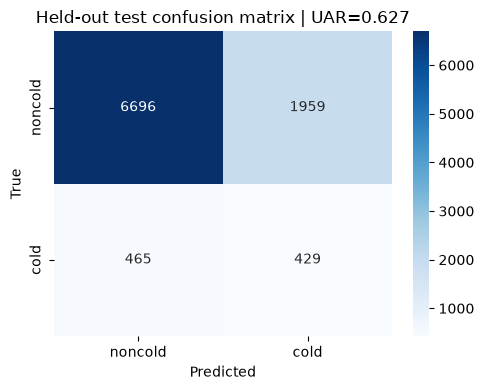

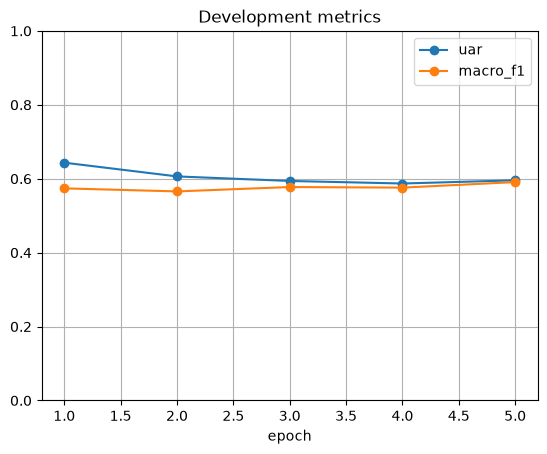

Saved results in: E:\Final Year Project\dataset\URTIC\cold_conformer_output\results_v4


In [7]:
# 7. Final held-out test evaluation and saved outputs
saved=torch.load(RESULTS_DIR/"best_conformer_v3.pt",map_location=DEVICE); model.load_state_dict(saved["state_dict"])
test_metrics,(y_true,y_pred,y_prob,paths)=evaluate(model,loaders["test"])
print(json.dumps(test_metrics,indent=2)); print("\n",classification_report(y_true,y_pred,target_names=["noncold","cold"],digits=4,zero_division=0))
with open(RESULTS_DIR/"test_metrics_v3.json","w") as f: json.dump(test_metrics,f,indent=2)
pd.DataFrame({"audio_path":paths,"target":y_true,"prediction":y_pred,"cold_probability":y_prob}).to_csv(RESULTS_DIR/"test_predictions_v3.csv",index=False)
cm=confusion_matrix(y_true,y_pred,labels=[0,1]); fig,ax=plt.subplots(figsize=(5,4)); sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["noncold","cold"],yticklabels=["noncold","cold"],ax=ax); ax.set(xlabel="Predicted",ylabel="True",title=f"Held-out test confusion matrix | UAR={test_metrics['uar']:.3f}"); fig.tight_layout(); fig.savefig(RESULTS_DIR/"test_confusion_matrix_v3.png",dpi=160); plt.show()
pd.DataFrame(history).plot(x="epoch",y=["uar","macro_f1"],marker="o",grid=True,title="Development metrics"); plt.ylim(0,1); plt.show()
print("Saved results in:",RESULTS_DIR)
